# 🚀 Session 9 – Unsupervised Learning: Clustering

⏱ Estimated Time: 90 minutes

---

## 🎯 A new kind of learning

Every model so far has been **supervised** — the data came with a **correct answer** (a label or a price) and the model learned to reproduce it. We could measure success because we knew the truth.

This session is different. We enter **unsupervised learning**, where the data has **no labels at all**. We are not predicting anything — we are **discovering structure** that is already hidden in the data.

> A retail manager in Dar es Salaam has thousands of loyalty-card customers but **no idea how to group them**. Are there "young big spenders"? "Wealthy but cautious" shoppers? Nobody labelled them. **Clustering** finds these natural groups automatically, so the business can market to each one differently. This is **customer segmentation**, and it is exactly what we build today.

We learn two clustering methods and the tools to use them well:

1. **k-Means clustering** — partition customers into *k* groups; choose *k* with the **elbow method** and **silhouette score**.
2. **Agglomerative (hierarchical) clustering** — build a tree of nested groups, visualised as a **dendrogram**.
3. **Preprocessing for clustering** — **scaling** (essential) and **PCA** (to reduce dimensions and visualise).
4. **Profiling** — interpret each cluster by its **average feature values** to give segments business meaning.

> 🆕 Clustering is a brand-new paradigm — there are **no train/test splits and no accuracy** here, because there is no "correct answer" to test against.

---

**Session Objective**
- Introduce clustering (**k-Means**, **hierarchical**); segment data **without labels** and evaluate **cluster cohesion**.
- Use **inertia + the elbow method** and the **silhouette score** to choose the number of clusters.
- Apply **feature scaling** and **PCA** before clustering, **visualise** clusters, and **interpret centroids**.

**Dataset:** a customer/marketing dataset (`mall_customers.csv`) for a retail loyalty programme.

## 🧩 Supervised vs Unsupervised — the key difference (10 minutes)

| | Supervised (Sessions 5–8) | Unsupervised (today) |
|---|---|---|
| **Data has labels?** | Yes (species, price, has-account) | **No** |
| **Goal** | Predict the label/value | **Discover** hidden groups/structure |
| **Train/test split?** | Yes | **No** (nothing to predict) |
| **Evaluation** | Accuracy, RMSE, F1 | **Inertia, silhouette** (cohesion/separation) |
| **Example** | "Will this loan default?" | "What types of customers do we have?" |

Because there is no ground truth, we judge a clustering by **how good the groups themselves are**:
- **Inertia** — the total squared distance from each point to its cluster's centre. **Lower = tighter clusters.** This is the *within-cluster* variance.
- **Silhouette score** — for each point, how much closer it is to its own cluster than to the nearest other cluster, averaged over all points. Ranges from −1 to +1; **higher = better separated**. This balances *within* vs *between* cluster variance.

### 🛠️ **The Implementation Flow**

#### **1. Import Libraries and Load Data**

In [1]:
## Import libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Each row is a loyalty-card customer. Notice there is **no "segment" or "type" column** — that is the whole point. We must *discover* the groups.

| Column | Meaning |
|--------|---------|
| `age` | Customer age in years |
| `monthly_income_k_tzs` | Monthly income in thousands of TZS |
| `spending_score` | Store-assigned spending score (1–100) |
| `visits_per_month` | Average store visits per month |
| `online_ratio` | Fraction of purchases made online (0–1) |

In [2]:
## Load the customer dataset
data = pd.read_csv('mall_customers.csv')
data.head()

customer_id,age,monthly_income_k_tzs,spending_score,visits_per_month,online_ratio
C0001,45,5369,33,1,0.08
C0002,35,1391,85,12,0.47
C0003,24,1633,25,6,0.32
C0004,41,2662,51,0,0.00
C0005,51,3603,24,7,0.33


In [3]:
# Shape and a quick statistical summary
print("Shape (customers, columns):", data.shape)
print()
print(data.describe().round(1))

Shape (customers, columns): (460, 6)

              age  monthly_income_k_tzs  spending_score  visits_per_month  online_ratio
count       460.0                 460.0           460.0             460.0         460.0
mean         39.8                2959.4            51.9               6.0           0.4
std          11.2                1590.9            24.0               3.6           0.2
min          18.0                 737.0             5.0               0.0           0.0
25%          30.0                1633.8            32.0               3.0           0.2
50%          40.0                2327.0            47.0               5.0           0.4
75%          47.0                4392.5            76.0               9.0           0.6
max          70.0                7032.0           100.0              16.0           1.0

A quick scatter of two features shows the raw data — just a cloud of dots with no grouping yet.

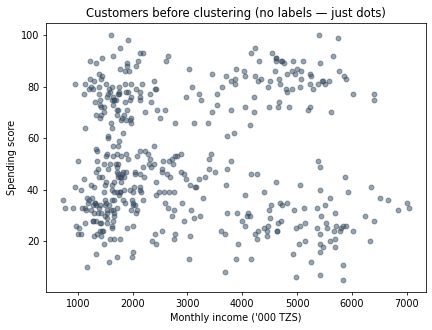

In [4]:
# Raw customers: income vs spending, no clusters yet
plt.scatter(data['monthly_income_k_tzs'], data['spending_score'], alpha=0.5, color='#34495e')
plt.xlabel("Monthly income ('000 TZS)")
plt.ylabel('Spending score')
plt.title('Customers before clustering (no labels — just dots)')
plt.show()

Our job: turn this undifferentiated cloud into meaningful **segments**.

## ⚖️ **Step 2: Scale the features (essential!)**

Clustering is **distance-based** — k-Means groups points that are close together. But our features are on wildly different scales: income runs into the **thousands** while `online_ratio` is between **0 and 1**. Without scaling, income would completely dominate every distance and the other features would be ignored.

> Just like for SVM and k-NN in Session 6, **we must standardise** so every feature contributes fairly. `StandardScaler` rescales each feature to mean 0, standard deviation 1.

In [5]:
# Select the numeric features (drop the ID — it carries no information)
features = ['age', 'monthly_income_k_tzs', 'spending_score', 'visits_per_month', 'online_ratio']
X = data[features].copy()

# Standardize: mean 0, std 1 for every feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Mean of each scaled feature (~0):", np.round(X_scaled.mean(axis=0), 2))
print("Std  of each scaled feature (~1):", np.round(X_scaled.std(axis=0), 2))

Scaled shape: (460, 5)
Mean of each scaled feature (~0): [ 0. -0.  0. -0.  0.]
Std  of each scaled feature (~1): [1. 1. 1. 1. 1.]

## 🎯 **k-Means Clustering**

k-Means is the most popular clustering algorithm. The idea:
1. Pick **k** (the number of clusters) and place k centre points (**centroids**) at random.
2. Assign each customer to the **nearest** centroid.
3. Move each centroid to the **average** of the points assigned to it.
4. Repeat 2–3 until the centroids stop moving.

The tricky part is choosing **k** — *how many segments are there?* We have two tools.

### 📐 The Elbow Method (using inertia)

We run k-Means for a range of k values and plot the **inertia** (total within-cluster squared distance). Inertia always falls as k grows (more clusters = tighter fit), but at some point the improvement **slows sharply** — the "elbow". That bend suggests a good k.

In [6]:
# Compute inertia for k = 1 to 10
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    print(f"k={k}: inertia = {km.inertia_:.1f}")

k=1: inertia = 2300.0
k=2: inertia = 1259.2
k=3: inertia = 1008.4
k=4: inertia = 764.0
k=5: inertia = 596.7
k=6: inertia = 549.2
k=7: inertia = 527.7
k=8: inertia = 490.3
k=9: inertia = 467.0
k=10: inertia = 448.4

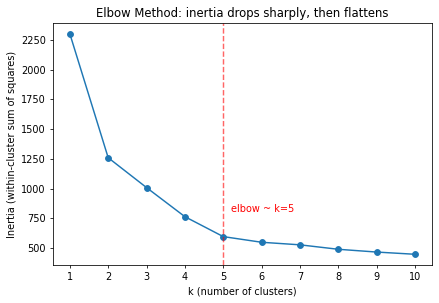

In [7]:
# Plot the elbow curve
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(5, color='red', linestyle='--', alpha=0.6)
plt.xticks(range(1, 11))
plt.xlabel('k (number of clusters)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.title('Elbow Method: inertia drops sharply, then flattens')
plt.show()

🔎 **Interpretation**: inertia plunges from k=1 to k=4–5, then the curve **flattens** — each extra cluster after that buys little. The "elbow" sits around **k=5**. Beyond it we would just be splitting hairs.

### 📊 The Silhouette Score

The elbow can be ambiguous, so we cross-check with the **silhouette score** — a direct measure of how well-separated the clusters are (higher is better).

In [8]:
# Silhouette score for k = 2 to 8
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_k)
    print(f"k={k}: silhouette = {score:.3f}")

k=2: silhouette = 0.414
k=3: silhouette = 0.317
k=4: silhouette = 0.357
k=5: silhouette = 0.374
k=6: silhouette = 0.346
k=7: silhouette = 0.307
k=8: silhouette = 0.299

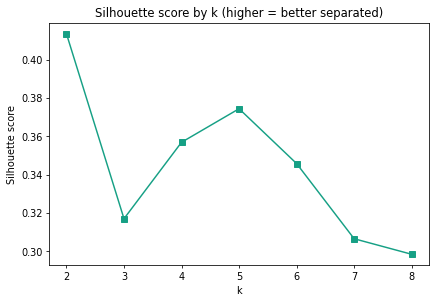

In [9]:
# Plot silhouette vs k
sils = [silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled))
        for k in range(2, 9)]
plt.plot(range(2, 9), sils, marker='s', color='#16a085')
plt.xticks(range(2, 9))
plt.xlabel('k'); plt.ylabel('Silhouette score')
plt.title('Silhouette score by k (higher = better separated)')
plt.show()

🔎 **Interpretation — an important real-world lesson**
- The silhouette is technically highest at **k=2** (0.414) — two very broad groups are the most "separated".
- But k=5 also scores well (0.374), and the **elbow** pointed to 5.
- **The metrics disagree, and that is normal.** Clustering has no single right answer. We combine the elbow, the silhouette, **and business sense**: the marketing team wants *actionable* segments, and 2 groups is too coarse to act on. **We choose k=5** — granular enough to be useful, supported by the elbow.

> Unsupervised learning always involves **judgement**. The metrics guide you; they do not decide for you.

### 🏗️ Fit the final k-Means with k=5

In [10]:
# Fit k-Means with the chosen k=5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Attach the cluster label to each customer
data['cluster'] = clusters

print("Cluster sizes:", np.bincount(clusters).tolist())
print(f"Final inertia:    {kmeans.inertia_:.1f}")
print(f"Silhouette score: {silhouette_score(X_scaled, clusters):.3f}")

Cluster sizes: [91, 84, 87, 79, 119]
Final inertia:    596.7
Silhouette score: 0.374

Five reasonably-sized segments (79–119 customers each) — no tiny or giant cluster, which is healthy.

## 🔻 **Visualising clusters with PCA**

We have **5 features**, but a screen has only **2 axes**. **Principal Component Analysis (PCA)** compresses the 5 features into 2 new "summary" axes (principal components) that capture as much of the variation as possible — letting us *see* the clusters.

<details>
<summary>What is PCA doing?</summary>

PCA finds new axes (combinations of the original features) ordered by how much **variance** they explain. PC1 captures the most spread, PC2 the next most, and so on. Plotting PC1 vs PC2 shows the data's main structure in 2-D. It is a **dimensionality-reduction** tool — useful for visualisation and for speeding up clustering on high-dimensional data.
</details>

In [11]:
# Reduce 5 features -> 2 components for plotting
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by each component:", np.round(pca.explained_variance_ratio_, 3).tolist())
print(f"Total variance captured in 2D: {pca.explained_variance_ratio_.sum():.1%}")

Variance explained by each component: [0.539, 0.228]
Total variance captured in 2D: 76.7%

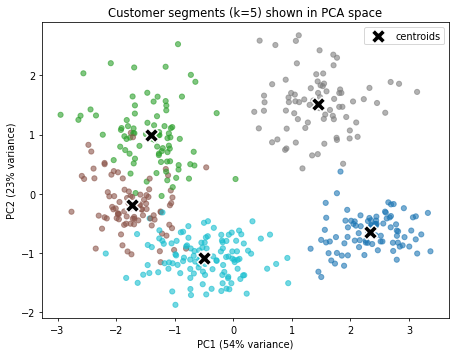

In [12]:
# Scatter plot in PCA space, coloured by cluster, with centroids
centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='tab10', alpha=0.6, s=28)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c='black', marker='X', s=220, edgecolor='white', linewidth=1.5, label='centroids')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% variance)')
plt.title('Customer segments (k=5) shown in PCA space')
plt.legend()
plt.show()

The 5 segments form **visibly distinct regions**, each with its centroid (black X). The 2 components capture **77%** of all the variation, so this picture is a faithful summary. We can also plot on the **original** axes — income vs spending — which are easier to interpret directly.

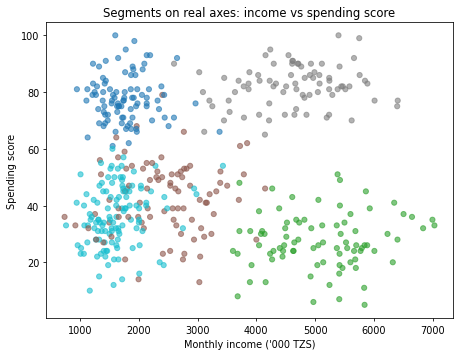

In [13]:
# Same clusters on real, interpretable axes
plt.figure(figsize=(8, 6))
plt.scatter(data['monthly_income_k_tzs'], data['spending_score'],
            c=clusters, cmap='tab10', alpha=0.6, s=28)
plt.xlabel("Monthly income ('000 TZS)")
plt.ylabel('Spending score')
plt.title('Segments on real axes: income vs spending score')
plt.show()

## 🔎 **Profiling the clusters — giving segments meaning**

A cluster number (0, 1, 2…) means nothing to a marketing team. The crucial final step is **profiling**: compute the **average feature values** in each cluster and read off *who these customers are*. This is interpreting the **centroids** in plain business language.

In [14]:
# Average feature values per cluster (in original units)
profile = data.groupby('cluster')[features].mean().round(1)
profile['size'] = data.groupby('cluster').size()
profile

cluster,age,monthly_income_k_tzs,spending_score,visits_per_month,online_ratio,size
0,26.1,1768.6,77.8,9.2,0.7,91
1,45.0,5099.5,27.5,4.1,0.3,84
2,53.8,2442.1,42.5,2.3,0.2,87
3,39.8,4629.3,82.1,10.6,0.5,79
4,36.2,1629.1,36.3,4.5,0.3,119


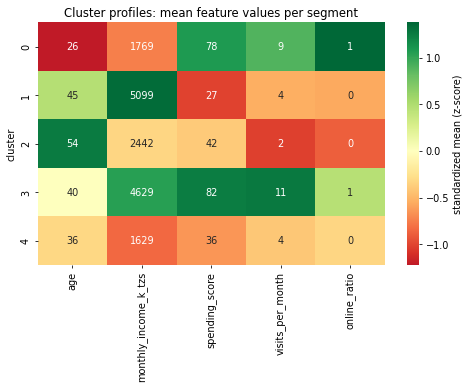

In [15]:
# A heatmap makes the profiles easy to compare at a glance
profile_means = data.groupby('cluster')[features].mean()
profile_z = (profile_means - X.mean()) / X.std()   # z-score for a fair colour scale

plt.figure(figsize=(9, 5))
sns.heatmap(profile_z, annot=profile_means.round(0).values, fmt='g',
            cmap='RdYlGn', center=0, cbar_kws={'label': 'standardized mean (z-score)'})
plt.title('Cluster profiles: mean feature values per segment')
plt.ylabel('cluster')
plt.show()

🔎 **Reading the profiles — naming our segments**
- **Cluster 0 — "Young Digital Spenders"**: youngest (26), low income, **high spending (78)**, frequent visits, **most online (0.7)**. Target with mobile/social campaigns.
- **Cluster 1 — "Affluent Cautious"**: **highest income (5.1M)** but **low spending (28)**. Money to spend, but not spending it — an upsell opportunity.
- **Cluster 2 — "Older Occasional"**: oldest (54), modest income, **rarely visits (2.3/mo)**, mostly offline. Win-back / retention focus.
- **Cluster 3 — "Premium Loyalists"**: high income **and** **highest spending (82)**, most frequent visitors. Your VIPs — reward and retain them.
- **Cluster 4 — "Budget Mainstream"**: the **largest group (119)**, younger, low income, modest spending. Value offers and loyalty points.

This is the **payoff** of clustering: five undifferentiated thousands of customers are now five **actionable** segments, each with its own marketing strategy.

**Practice Task:**
1. Re-run k-Means with **k=4** and again with **k=6**. Profile each. Do the segments still tell a clear story, or do some become hard to name?
2. Which k gives the most *business-actionable* segments? Justify using both the profiles and the silhouette score.

In [ ]:
# Your code here


## 🌳 **Agglomerative (Hierarchical) Clustering**

k-Means needs you to fix **k** up front. **Agglomerative clustering** takes a different, bottom-up approach:
1. Start with every customer as its **own** cluster.
2. Repeatedly **merge** the two closest clusters.
3. Continue until everything is one big cluster.

This builds a **tree of nested groupings** called a **dendrogram**, which lets you *see* the structure at every level and decide where to "cut".

<details>
<summary>What is 'linkage'?</summary>

**Linkage** defines the distance between two *clusters* (not just two points). **Ward linkage** (the common default) merges the pair that increases total within-cluster variance the least — it tends to produce compact, balanced clusters, much like k-Means.
</details>

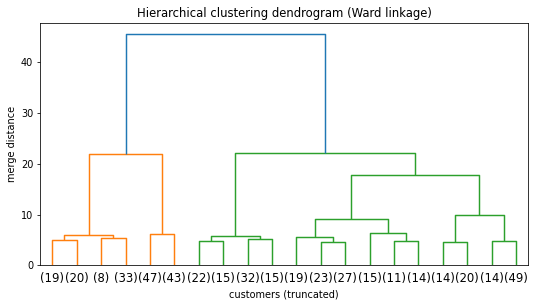

In [16]:
# Build a dendrogram using SciPy (shows the merge hierarchy)
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=20, color_threshold=0.7 * max(Z[:, 2]))
plt.title('Hierarchical clustering dendrogram (Ward linkage)')
plt.xlabel('customers (truncated groups)')
plt.ylabel('merge distance')
plt.show()

🔎 **Reading the dendrogram**: the **height** of each merge is the distance at which groups joined. Tall vertical lines = very different groups merging. To pick the number of clusters, imagine a **horizontal cut** — the number of vertical lines it crosses is the number of clusters. Cutting near the tall gap here yields about **5** groups, agreeing with our elbow analysis.

Now apply `AgglomerativeClustering` directly with k=5 and compare it to k-Means.

In [17]:
# Agglomerative clustering with 5 clusters
agg = AgglomerativeClustering(n_clusters=5, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)

print("Agglomerative cluster sizes:", np.bincount(agg_labels).tolist())
print(f"Agglomerative silhouette: {silhouette_score(X_scaled, agg_labels):.3f}")
print(f"k-Means silhouette:       {silhouette_score(X_scaled, clusters):.3f}")

Agglomerative cluster sizes: [97, 109, 84, 80, 90]
Agglomerative silhouette: 0.363
k-Means silhouette:       0.374

🔎 **Interpretation**: hierarchical clustering finds **very similar** segments (comparable sizes, almost the same silhouette). When two different algorithms agree, you can be **more confident** the structure is real and not an artefact of one method.

| | k-Means | Agglomerative |
|---|---|---|
| Must choose k upfront? | Yes | No (cut the tree afterwards) |
| Speed on big data | Fast | Slower (compares all pairs) |
| Output | Flat clusters + centroids | Full hierarchy (dendrogram) |
| Shape assumption | Roughly spherical | More flexible |

## 🔻 **A closer look at PCA (dimensionality reduction)**

PCA is useful beyond plotting — on datasets with **many** features, clustering in the full space can be slow and noisy. Reducing to a few components first often helps. Here is how much variance each component captures.

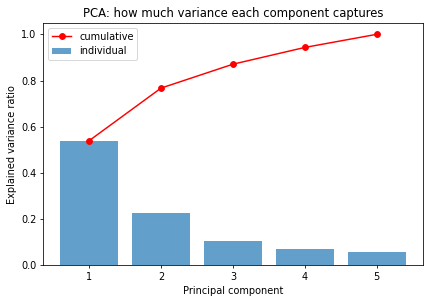

In [18]:
# How many components do we really need?
pca_full = PCA().fit(X_scaled)

plt.bar(range(1, 6), pca_full.explained_variance_ratio_, alpha=0.7, label='individual')
plt.plot(range(1, 6), np.cumsum(pca_full.explained_variance_ratio_),
         marker='o', color='red', label='cumulative')
plt.xticks(range(1, 6))
plt.xlabel('Principal component'); plt.ylabel('Explained variance ratio')
plt.title('PCA: how much variance each component captures')
plt.legend()
plt.show()

🔎 The first **2 components** capture ~77% and the first **3** capture most of the variance. So we could cluster on just 2–3 PCA components instead of all 5 features — handy when datasets have dozens or hundreds of columns.

##### 🧠 Key takeaways
- **Unsupervised learning** finds structure with **no labels** — no train/test split, no accuracy.
- **k-Means** partitions into k clusters; pick k with the **elbow method (inertia)** + **silhouette score** + **business sense**.
- **Inertia** = within-cluster tightness (lower better); **silhouette** = separation (higher better).
- **Scaling is essential** before clustering (it is distance-based).
- **PCA** reduces dimensions for visualisation and speed.
- **Agglomerative clustering** builds a **dendrogram**; agreement between methods boosts confidence.
- **Profiling centroids** turns anonymous cluster numbers into **actionable customer segments** — the real business value.

## 🛠️ Mini Project: Segment the Customers (20 minutes)

**Scenario:** The marketing team wants a customer segmentation they can act on, using `mall_customers.csv`.

**Preprocess:**
* Load the data, select the numeric features, and **scale** them with `StandardScaler`.

**Choose k:**
* Compute inertia for k = 1–10 and plot the **elbow**.
* Compute the **silhouette** for k = 2–8.
* Decide on a k, justifying it with both metrics **and** business sense.

**Cluster:**
* Fit `KMeans` with your chosen k and attach labels to the customers.
* Report cluster sizes, inertia and silhouette.

**Visualise:**
* Use **PCA** to plot the clusters in 2-D (with centroids).
* Also plot on two original axes (e.g. income vs spending).

**Profile & Name:**
* Compute the mean feature values per cluster.
* Give each segment a short, descriptive **name** and a one-line marketing recommendation.

**Compare:**
* Run `AgglomerativeClustering` with the same k. Do the segments agree with k-Means?

Write Markdown notes at each step. Remember: there is no single right answer — defend your choices.

## 🚀 Capstone Project: Customer Segmentation End-to-End (25 minutes)

Deliver a complete customer-segmentation analysis a business could act on.

**Dataset:** `mall_customers.csv` (or any customer/marketing dataset with relevant numeric features, e.g. from Kaggle).

**Tasks:**
1. **Load & Explore:** Load the data, summarise the features, and plot a couple of raw scatter plots. Note that there are **no labels** — this is unsupervised.
2. **Preprocess:** Select numeric features and **scale** them. Explain why scaling is essential for distance-based clustering.
3. **Choose k (k-Means):** Use the **elbow method** (inertia) and the **silhouette score** to choose the number of clusters. Show both plots and justify your choice.
4. **Cluster with k-Means:** Fit the model; report cluster sizes, inertia, and silhouette.
5. **Dimensionality Reduction:** Apply **PCA** to 2 components; report variance explained; plot the clusters with centroids in PCA space.
6. **Profile the Clusters:** Compute mean feature values per cluster; present a profile table/heatmap; **name** each segment and describe it in business terms.
7. **Hierarchical Clustering:** Build a **dendrogram**, then fit `AgglomerativeClustering` with your chosen k. Compare its segments and silhouette to k-Means.
8. **Recommendations:** For each segment, give a concrete marketing action (e.g. channel, offer, retention vs acquisition).
9. **Reflection:** Discuss the limitations — why clustering has no single "correct" answer, and how you used metrics plus judgement to decide.

**Deliverable:** A Jupyter notebook with all code, outputs, plots (elbow, silhouette, PCA scatter, dendrogram, profile heatmap), named segments with recommendations, and a short written conclusion.

By completing this capstone, learners demonstrate mastery of k-Means and hierarchical clustering, the elbow and silhouette methods, scaling and PCA preprocessing, cluster visualisation, and the interpretation of centroids into actionable customer segments.